# Análise de Dados de Internamentos Hospitalares
Este notebook executa a análise exploratória e estatística carregando os dados diretamente a partir de um ficheiro CSV externo.

## 1. Importação de Bibliotecas e Leitura do Ficheiro CSV

In [19]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
# Visual style configuration for plots
sns.set_theme(style="whitegrid")

# Define file path by navigating 3 levels up from the current working directory
file_path = (Path.cwd() / "../../../tools/data-generation/output/dataset.csv").resolve()

# Check if the file exists before reading
if file_path.exists():
    df = pd.read_csv(file_path)
    print(f"File successfully loaded from: {file_path}\n")
else:
    print(f"Error: File not found at path:\n{file_path}")
    df = None

File successfully loaded from: C:\Users\RuiMiguelSoaresRodri\Desktop\Mestrado\2_Ano\PI\PatientFlow\tools\data-generation\output\dataset.csv



## 2. Processamento e Cálculo de Métricas (Idade e Tempo de Internamento)

In [20]:
if df is not None:
  # Converter colunas de data/hora para o formato datetime
  df["birthdate"] = pd.to_datetime(df["birthdate"])
  df["admission date"] = pd.to_datetime(df["admission date"])
  df["discharge date"] = pd.to_datetime(df["discharge date"])

  # 1. Renomear colunas se necessário (ex: 'diagnosis code')
  df = df.rename(columns={"diagnosis code": "diagnosis_code"})

  # 2. Calcular a idade na data de admissão (em anos)
  df["age"] = (
      (df["admission date"] - df["birthdate"]).dt.days / 365.25
  ).astype(int)

  # 3. Calcular o Tempo de Internamento (LOS) em dias completos
  df["los_days"] = (df["discharge date"] - df["admission date"]).dt.days

  # 4. Extrair o mês e o dia da semana da data de admissão
  df["month"] = df["admission date"].dt.month
  df["admission_weekday"] = df["admission date"].dt.day_name()

  # 5. Determinar a altura do dia
  def get_period_of_day(hour):
    if 6 <= hour < 12:
      return "Morning"
    elif 12 <= hour < 18:
      return "Afternoon"
    elif 18 <= hour < 24:
      return "Evening"
    else:
      return "Night"

  df["time_period"] = df["admission date"].dt.hour.apply(get_period_of_day)

  # 6. Determinar a estação do ano
  def get_season(date):
    month = date.month
    day = date.day
    if (month == 12 and day >= 21) or month in [1, 2] or (month == 3 and day < 20):
      return "Winter"
    elif (
        (month == 3 and day >= 20) or month in [4, 5] or (month == 6 and day < 21)
    ):
      return "Spring"
    elif (
        (month == 6 and day >= 21) or month in [7, 8] or (month == 9 and day < 23)
    ):
      return "Summer"
    else:
      return "Autumn"

  df["season"] = df["admission date"].apply(get_season)

  # 7. Manter as colunas pretendidas (incluindo 'specialty')
  columns_to_keep = [
      "gender",
      "specialty",
      "diagnosis_code",
      "age",
      "los_days",
      "month",
      "admission_weekday",
      "time_period",
      "season",
  ]
  df = df[columns_to_keep]

  display(df.head())

,gender,specialty,diagnosis_code,age,los_days,month,admission_weekday,time_period,season
0,F,CIR,K56.60,73,5,9,Thursday,Morning,Autumn
1,F,MED,R65.21,40,9,9,Thursday,Morning,Autumn
2,F,CIR,K80.20,78,3,9,Friday,Morning,Autumn
3,M,CIR,K80.20,71,4,9,Friday,Morning,Autumn
4,M,MED,R65.21,93,9,9,Friday,Afternoon,Autumn


## 3. Resumo Estatístico dos Dados

In [21]:
if df is not None:
  print("=== GENERAL STATISTICS ===")
  print(f"Total patients: {len(df)}")
  print(f"Average age: {df['age'].mean():.1f} years")
  print(f"Average length of stay: {df['los_days'].mean():.2f} days")

  print("\n=== GENDER DISTRIBUTION ===")
  print(df["gender"].value_counts())

  print("\n=== SPECIALTY DISTRIBUTION ===")
  print(df["specialty"].value_counts())

  print("\n=== COUNT BY ICD-10 DIAGNOSIS CODE ===")
  print(df["diagnosis_code"].value_counts())

  print("\n=== ADMISSIONS BY SEASON ===")
  print(df["season"].value_counts())

=== GENERAL STATISTICS ===
Total patients: 27465
Average age: 70.4 years
Average length of stay: 7.80 days

=== GENDER DISTRIBUTION ===
gender
M    13812
F    13653
Name: count, dtype: int64

=== SPECIALTY DISTRIBUTION ===
specialty
MED    15381
CIR    11055
UCI     1029
Name: count, dtype: int64

=== COUNT BY ICD-10 DIAGNOSIS CODE ===
diagnosis_code
K56.60    2278
K80.20    2250
C18.9     2226
K35.80    2193
K40.90    2133
E86.0     1990
N39.0     1968
J18.9     1928
D64.9     1921
N17.9     1842
I50.9     1821
I46.9     1259
R65.21    1254
A41.9     1208
J96.00    1194
Name: count, dtype: int64

=== ADMISSIONS BY SEASON ===
season
Spring    7652
Winter    7317
Autumn    7227
Summer    5269
Name: count, dtype: int64


## 4. Visualização Gráfica

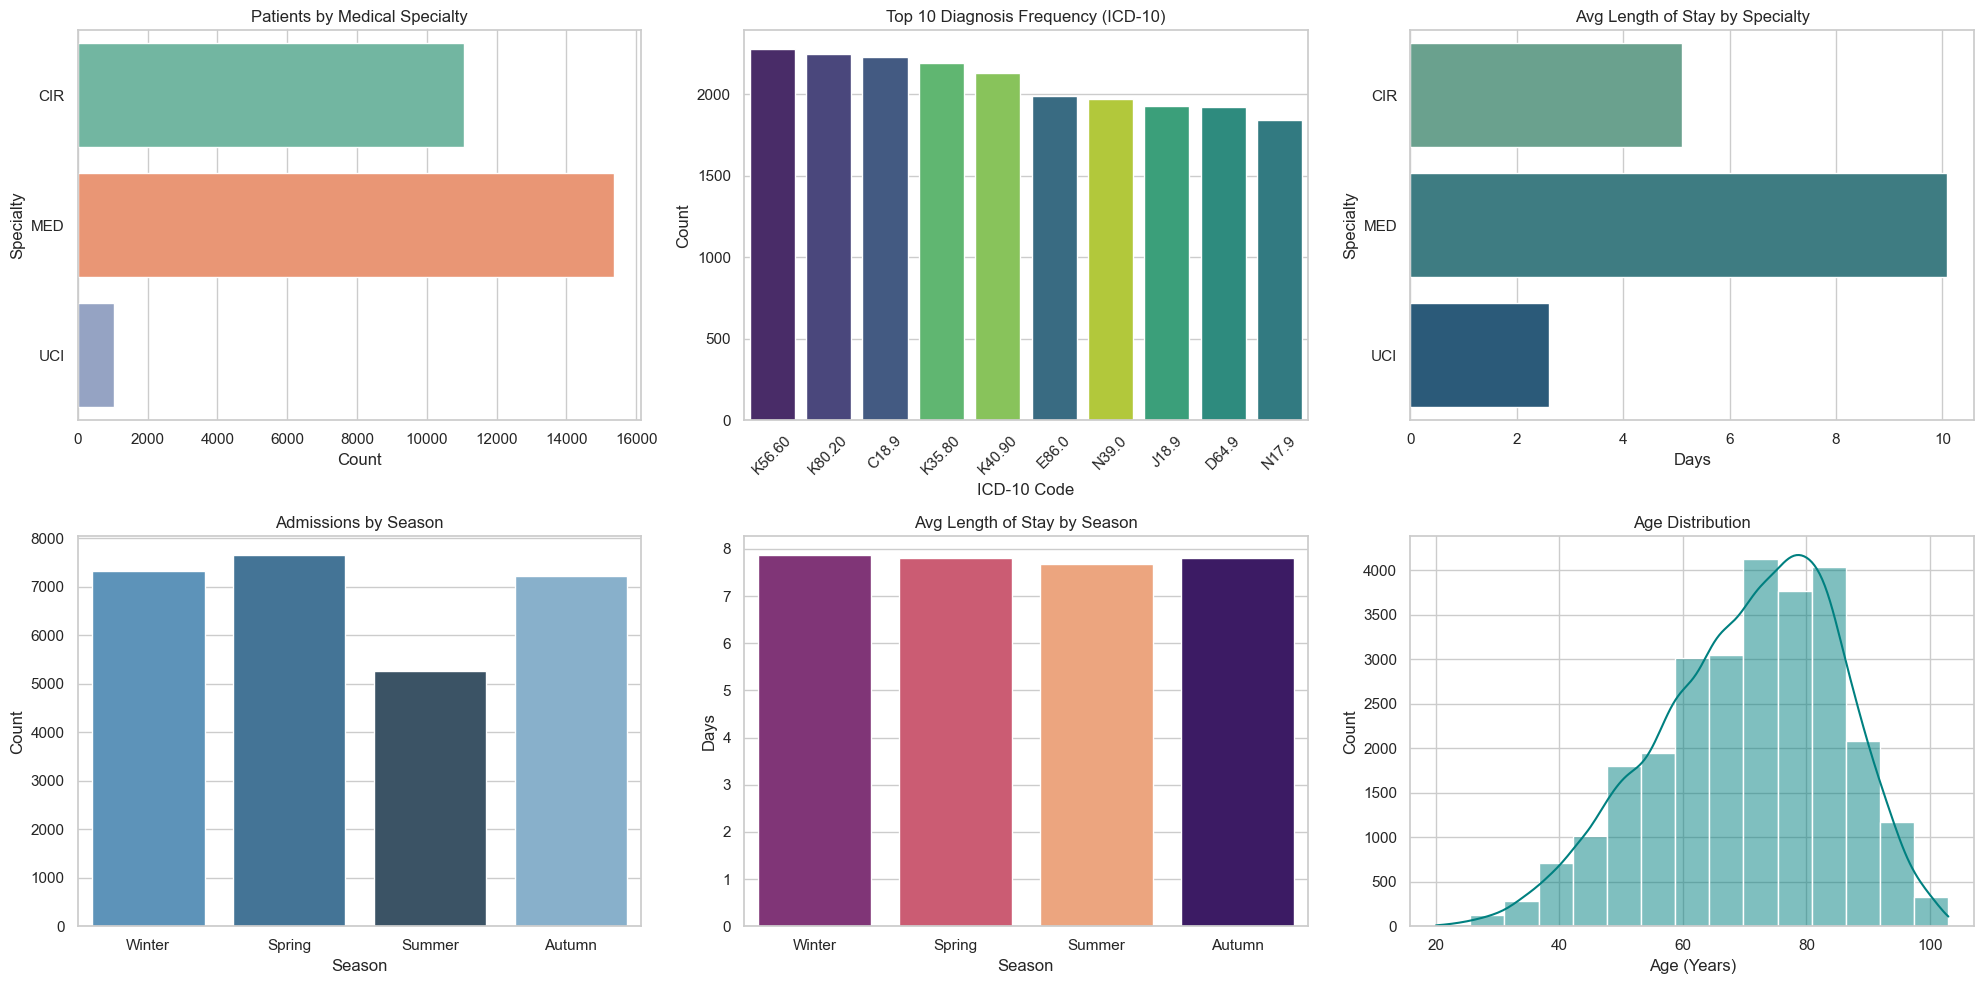

In [22]:
if df is not None:
  fig, axes = plt.subplots(2, 3, figsize=(20, 10))

  top_10_diag = df["diagnosis_code"].value_counts().head(10).index
  df_top10 = df[df["diagnosis_code"].isin(top_10_diag)]

  # 1. Specialty Distribution (Linha 0, Coluna 0 - Substitui o Género ou entra como nova)
  sns.countplot(
      data=df,
      y="specialty",
      hue="specialty",
      palette="Set2",
      legend=False,
      ax=axes[0, 0],
  )
  axes[0, 0].set_title("Patients by Medical Specialty")
  axes[0, 0].set_xlabel("Count")
  axes[0, 0].set_ylabel("Specialty")

  # 2. Top 10 Diagnosis Frequency (Linha 0, Coluna 1)
  sns.countplot(
      data=df_top10,
      x="diagnosis_code",
      hue="diagnosis_code",
      palette="viridis",
      order=top_10_diag,
      legend=False,
      ax=axes[0, 1],
  )
  axes[0, 1].set_title("Top 10 Diagnosis Frequency (ICD-10)")
  axes[0, 1].set_xlabel("ICD-10 Code")
  axes[0, 1].set_ylabel("Count")
  axes[0, 1].tick_params(axis="x", rotation=45)

  # 3. Average Length of Stay by Specialty (Linha 0, Coluna 2)
  sns.barplot(
      data=df,
      y="specialty",
      x="los_days",
      hue="specialty",
      palette="crest",
      errorbar=None,
      legend=False,
      ax=axes[0, 2],
  )
  axes[0, 2].set_title("Avg Length of Stay by Specialty")
  axes[0, 2].set_xlabel("Days")
  axes[0, 2].set_ylabel("Specialty")

  # 4. Admissions by Season (Linha 1, Coluna 0)
  sns.countplot(
      data=df,
      x="season",
      hue="season",
      palette="Blues_d",
      order=["Winter", "Spring", "Summer", "Autumn"],
      legend=False,
      ax=axes[1, 0],
  )
  axes[1, 0].set_title("Admissions by Season")
  axes[1, 0].set_xlabel("Season")
  axes[1, 0].set_ylabel("Count")

  # 5. Average Length of Stay by Season (Linha 1, Coluna 1)
  sns.barplot(
      data=df,
      x="season",
      y="los_days",
      hue="season",
      palette="magma",
      order=["Winter", "Spring", "Summer", "Autumn"],
      errorbar=None,
      legend=False,
      ax=axes[1, 1],
  )
  axes[1, 1].set_title("Avg Length of Stay by Season")
  axes[1, 1].set_xlabel("Season")
  axes[1, 1].set_ylabel("Days")

  # 6. Age Distribution (Linha 1, Coluna 2)
  sns.histplot(data=df, x="age", kde=True, color="teal", bins=15, ax=axes[1, 2])
  axes[1, 2].set_title("Age Distribution")
  axes[1, 2].set_xlabel("Age (Years)")
  axes[1, 2].set_ylabel("Count")

  plt.tight_layout()
  plt.show()

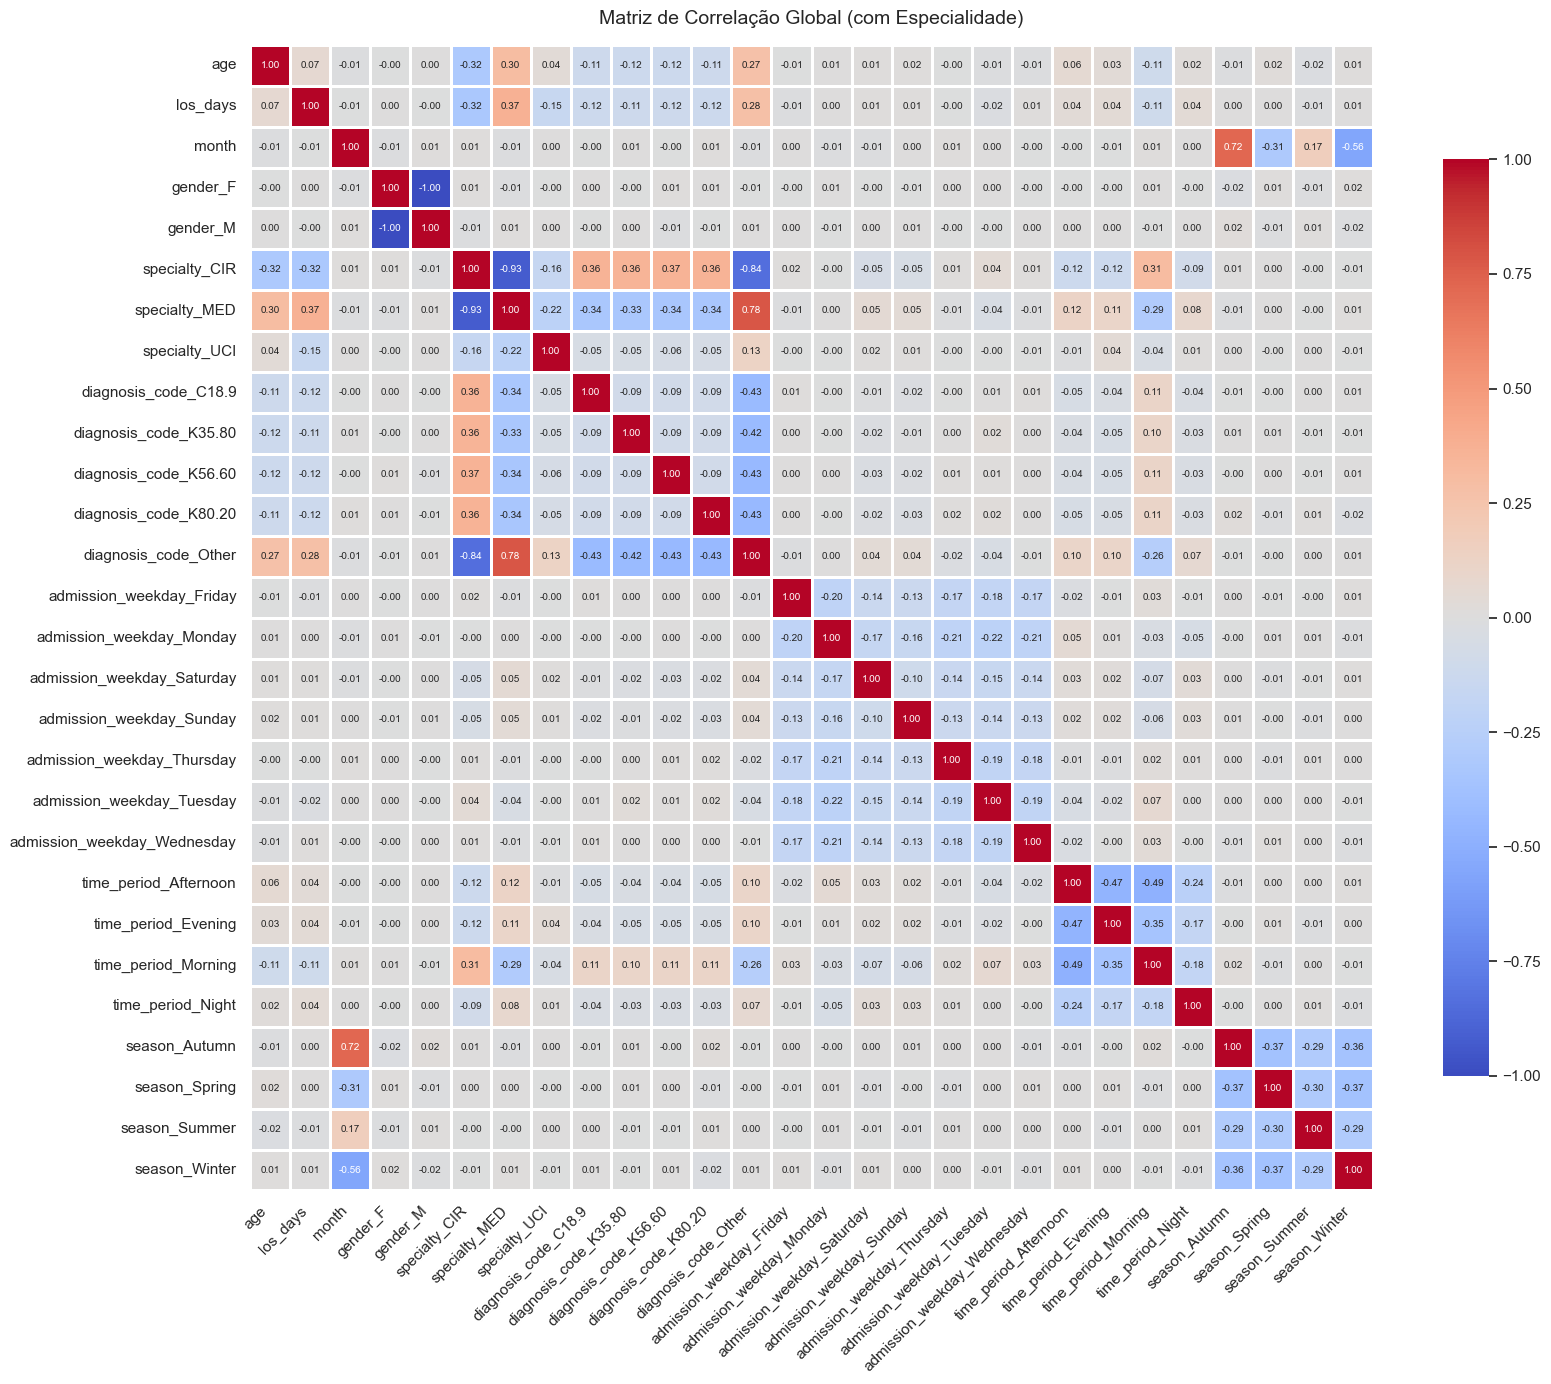

In [23]:
if df is not None:
    df_clean = df.copy()

    # 1. Manter os 4 diagnósticos mais frequentes e agrupar o resto em 'Other'
    top_4_diag = df_clean['diagnosis_code'].value_counts().head(4).index
    df_clean['diagnosis_code'] = df_clean['diagnosis_code'].apply(
        lambda x: x if x in top_4_diag else 'Other'
    )

    # 2. Converter variáveis categóricas sem eliminar a primeira categoria
    df_encoded = pd.get_dummies(df_clean)

    # 3. Calcular a matriz de correlação completa
    corr = df_encoded.corr()

    # 4. Ajustar dinamicamente o tamanho da figura consoante o número de variáveis
    n_vars = len(corr.columns)
    plt.figure(figsize=(max(12, n_vars * 0.6), max(10, n_vars * 0.5)))

    # 5. Desenhar o heatmap
    sns.heatmap(
        corr,
        annot=True,
        fmt='.2f',
        annot_kws={'size': max(6, 10 - n_vars * 0.1)},
        cmap='coolwarm',
        vmin=-1.0,
        vmax=1.0,
        linewidths=0.8,
        linecolor='white',
        cbar_kws={'shrink': 0.8},
    )

    plt.title(
        'Matriz de Correlação Global (com Especialidade)', fontsize=14, pad=15
    )
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

In [24]:
import scipy.stats as stats

if df is not None:
  print(
      "--- 1. DIFERENÇA DE TEMPO DE INTERNAMENTO (LOS) POR ESPECIALIDADE ---"
  )
  groups_spec = [
      group["los_days"].dropna() for name, group in df.groupby("specialty")
  ]
  f_stat, p_val = stats.f_oneway(*groups_spec)
  print(f"ANOVA (LOS vs Specialty): p-value = {p_val:.4f}")
  if p_val < 0.05:
    print(
        "-> Existe diferença estatisticamente significativa no tempo de"
        " internamento entre as especialidades médicas!\n"
    )
  else:
    print(
        "-> Não há diferença significativa no tempo de internamento entre"
        " especialidades.\n"
    )

  print("--- 2. ASSOCIAÇÃO ENTRE ESPECIALIDADE E DIAGNÓSTICO ---")
  contingency_spec = pd.crosstab(df["specialty"], df["diagnosis_code"])
  chi2, p_val_spec, dof, ex = stats.chi2_contingency(contingency_spec)
  print(f"Qui-Quadrado (Specialty vs Diagnosis): p-value = {p_val_spec:.4f}")
  if p_val_spec < 0.05:
    print(
        "-> Existe uma associação forte e estatisticamente significativa entre a"
        " especialidade e o tipo de diagnóstico!\n"
    )
  else:
    print("-> A distribuição de diagnósticos é independente da especialidade.\n")

--- 1. DIFERENÇA DE TEMPO DE INTERNAMENTO (LOS) POR ESPECIALIDADE ---
ANOVA (LOS vs Specialty): p-value = 0.0000
-> Existe diferença estatisticamente significativa no tempo de internamento entre as especialidades médicas!

--- 2. ASSOCIAÇÃO ENTRE ESPECIALIDADE E DIAGNÓSTICO ---
Qui-Quadrado (Specialty vs Diagnosis): p-value = 0.0000
-> Existe uma associação forte e estatisticamente significativa entre a especialidade e o tipo de diagnóstico!



In [25]:
output_filename = "ml_hospital_consumption_27k.csv"

try:
    df.to_csv(output_filename, index=False, encoding='utf-8-sig')
    print(f"Ficheiro guardado com sucesso: {output_filename}")
except Exception as e:
    print(f"Erro ao guardar o ficheiro CSV: {e}")

Ficheiro guardado com sucesso: ml_hospital_consumption_27k.csv
